# **1. AI Agent**

- LLM(Large Language Model): 사용자의 입력을 읽고 문장을 생성하는 언어 모델. 단독으로는 일반적으로 외부 웹사이트 검색, 파일 수정, 실제 예약을 실행하지 않음
- AI Agent(인공지능 에이전트): 목표를 달성하기 위해 현재 상태 / 환경을  관찰하고, 다음 행동을 결정하고, 필요한 도구를 사용한 뒤 결과를 다시 확인하는 시스템
- LLM 기반 Agent: LLM을 의사결정 구성요로 활용하고 도구와 실행 제어를 결합한 Agent

```
예시
"서울 날씨가 비라면 우산을 챙기라고 알려줘."

1. 목표: 비 여부에 따른 안내가 필요
2. 도구 선택: 날씨 조회 도구가 필요 
3. 도구 실행: 날씨 API가 실제 관측/예보 정보를 반환\
4. 결과 해석: 비가 예상되는지 확인
5. 응답: 우산을 챙기라는 안내 또는 필요 없다는 안내를 생성
```

> 모든 Agent가 LLM을 사용하는 것은 아님. 로봇청소기나 게임 AI도 넓은 의미의 Agent가 될 수 있음

### Agent의 구성요소
- 목표: 무엇을 달성해야 하는가?
- Model/Policy: 다음 행동을 어떻게 선택하는가?
- Tools: 검색, 계산, DB 조회, API 요청 등 실제 작업을 수행
- Memory: 실행 중 대화 이력 또는 장기 정당된 정보를 활용
- State: 질문, 결과, 현재 단계 등을 담음
- 평가: 권한, 승인, 종료 조건, 결과 품질을 점검

### 그래프(Graph)
그래프는 노드와 엣지로 구성된 연결 구조
- 노드: 사람, 작업 처럼 하나의 대상 또는 처리 단위
- 엣지: 두 노드 사이의 관계 또는 이동 경로
- 방향 그래프: A -> B 처럼 연결되는 방향이 있음
- 사이클: A -> B -> A 처럼 다시 돌아오는 경로가 있음

> LangGraph에서는 노드를 "실행할 함수", 엣지를 "다음에 실행할 노드로 이동하는 규칙"으로 사용

```
예)
START -> 질문 분석 -> 답변 생성 -> END
            -> 검색 -> 

```

### 랭체인(LangChain)
- 랭체인은 대형 언어 모델을 활용한 애플리케이션을 쉽게 개발할 수 있도록 다양한 기능을 제공하는 프레임워크
- 프롬프트 관리, 문서 검색, 벡터 데이터베이스 연동, 체인 구조를 통한 여러 작업의 연결, 그리고 외부 도구 사용 등을 하나의 흐름으로 구성할 수 있게 해줌
- 챗봇, 문서 기반 질의 응답(RAG), 에이전트 시스템과 같은 AI서비스를 효율적으로 구축

### LangGraph(랭그래프)
- LangChain 생태계에서 에이전트나 RAG 시스템을 단계별로 구성하고 실행할 수 있게 해주는 그래프 기반 오케스트레이션 프레임워크
- 기존 RAG가 직선형 파이프라인이었다면, 랭그래프는 노드(작업 단위)와 엣지(흐름)을 그래프 형태로 정의해 분기, 반복, 조건 처리, 에이전트 루프 같은 복잡한 흐름을 명확하게 표현하고 실행

### 랭그래프의 구성요소
1. 노드(Node)
- 노드는 LangGraph 워크플로우 안에서 실행되는 개별 작업 단위
- 예) "질문을 임베딩하기", "벡터 DB에서 관련 문서 검색하기", "LLM으로 답변 생성하기" 같은 단계가 각각 하나의 노드가 됨
- 노드는 전체 워크플로우를 이루는 핵심 블록

2. 엣지(Edge)
- 엣지는 노드와 노드를 연결하는 흐름을 의미
- 한 노드의 결과가 다음 노드의 입력을 이어지도록 만들어 주며, 워크플로우가 순차적으로 진행할 수 있게 함

3. 상태(State)
- 상태는 워크플로우 실행 중 유지되고 공유되는 데이터 저장소
- 사용자 질문, 검색 결과, 현재까지의 답변 초안 등이 상태에 담겨 각 노드가 읽고 쓸 수 있음
- 상태 덕분에 그래프 전체가 일관된 맥락을 유지할 수 있음

- TypedDict: 파이썬의 typing 모듈에서 제공하며, 딕셔너리의 키와 값의 타입을 정의
- BaseModel: Pydantic 라이브러리에서 제공

In [20]:
from typing import TypedDict

In [21]:
class User(TypedDict):
    id: int
    name: str
    email: str

In [22]:
# 이런식으로 채울 수 있음
user1: User = {"id": 1 , "name": "김사과", "email": "apple@apple.com"}
print(user1)

# 오류는 안 나지만 이딴식으로 하면 안됨
user2: User = {"id": 2 , "name": 1000,  "email": "apple@apple.com"}
user2

{'id': 1, 'name': '김사과', 'email': 'apple@apple.com'}


{'id': 2, 'name': 1000, 'email': 'apple@apple.com'}

In [23]:
from pydantic import BaseModel # pip install pydantic

In [24]:
class User(BaseModel):
    id: int
    name: str
    email: str

In [26]:
# 이런식으로 채울 수 있음
user1: User = {"id": 1 , "name": "김사과", "email": "apple@apple.com"}
print(user1)

# 오류는 안 나지만 이딴식으로 하면 안됨
user2: User = {"id": 2 , "name": 1000,  "email": "apple@apple.com"}
print(user2)

user3: User = {"id": 2 , "name": 1000,  "email": "apple@apple.com"}
user3

{'id': 1, 'name': '김사과', 'email': 'apple@apple.com'}
{'id': 2, 'name': 1000, 'email': 'apple@apple.com'}


{'id': 2, 'name': 1000, 'email': 'apple@apple.com'}

### 랭그래프이긴 한데 작은 제목 강사님은 추가 X

In [27]:
from langgraph.graph import StateGraph, START, END # pip install langgraph

In [28]:
class HelloState(TypedDict):
    name: str
    greeting: str

def greeting_node(state: HelloState):
    return {"greeting": f"안녕하세요, {state['name']}님!"}

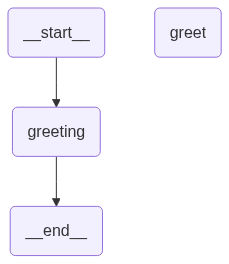

In [ ]:
hello_builder = StateGraph(HelloState) # 객체 자체를 넣어야 메모리로써 사용할 수 있음
hello_builder.add_node("greeting", greeting_node)
# hello_builder.add_node("greet", greeting_node)

hello_builder.add_edge(START, "greeting")
hello_builder.add_edge("greeting", END)

# 강사님은 greeting -> END로 
# hello_builder.add_edge("greeting", "greet")
# hello_builder.add_edge("greet", END)

# 자기 참조
# hello_builder.add_edge("greeting", "greeting")
# hello_builder.add_edge("greeting", END)
hello_graph = hello_builder.compile()
hello_graph

In [44]:
print(hello_graph.invoke({"name":"김사과", "greeting": ""}))

{'name': '김사과', 'greeting': '안녕하세요, 김사과님!'}


In [45]:
from typing import Annotated
import operator

In [50]:
# 그냥 아래 operator.add(a, b) 예시 코드임 필요 없음
a = 10
b = 20
print(operator.add(a, b))

30


In [ ]:
# 하나의 모듈임
class HistoryState(TypedDict):
    # Annotated: 기존 타입에 추가적인 정보를 붙일 수 있는 기능
    # operator.add: 병합 함수 <- 콜백으로 등록 되어있음 예) operator.add(a, b)는 a+b 연산을 수행
    history: Annotated[list[str], operator.add]  # history에 계속 남음

def first_note(state: HistoryState):
    return {"history": ["1단계"]}

def second_note(state: HistoryState):
    return {"history": ['2단계']}

In [48]:
history_bilder = StateGraph(HistoryState)
history_bilder.add_node("first", first_note)
history_bilder.add_node("second", second_note)

history_bilder.add_edge(START, "first")
history_bilder.add_edge("first", "second")
history_bilder.add_edge("second", END)
history_graph = history_bilder.compile()

In [49]:
print(history_graph.invoke({"history": []}))

{'history': ['1단계', '2단계']}
